In [1]:
 import numpy as np

In [2]:
n_saves, n_bins, L = 100, 100, 2.0        # must match the C++ settings
counts = np.fromfile("run_counts.bin", dtype=np.int64)
counts = counts.reshape(n_saves + 1, n_bins, n_bins)
t_history = np.fromfile("run_t.bin", dtype=np.float64)

# same normalization as np.histogram2d(..., density=True)
bin_area = (2 * L / n_bins) ** 2
P_history = counts / (counts.sum(axis=(1, 2), keepdims=True) * bin_area)
bins = np.linspace(-L, L, n_bins + 1)     # for the plotting/RMS cells

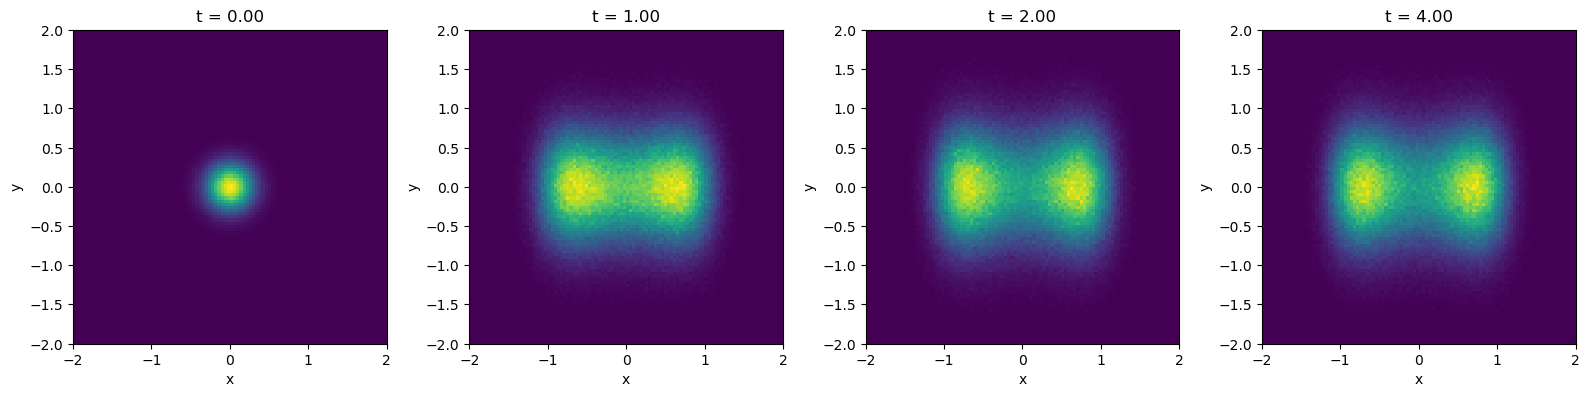

In [3]:
import matplotlib.pyplot as plt

frames = [0, 25, 50, 100]

fig, axes = plt.subplots(1, len(frames), figsize=(4 * len(frames), 4))
for ax, k in zip(axes, frames):
    ax.imshow(P_history[k].T, origin="lower", extent=[-L, L, -L, L], cmap="viridis")
    ax.set_title(f"t = {t_history[k]:.2f}")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
plt.tight_layout()
plt.show()

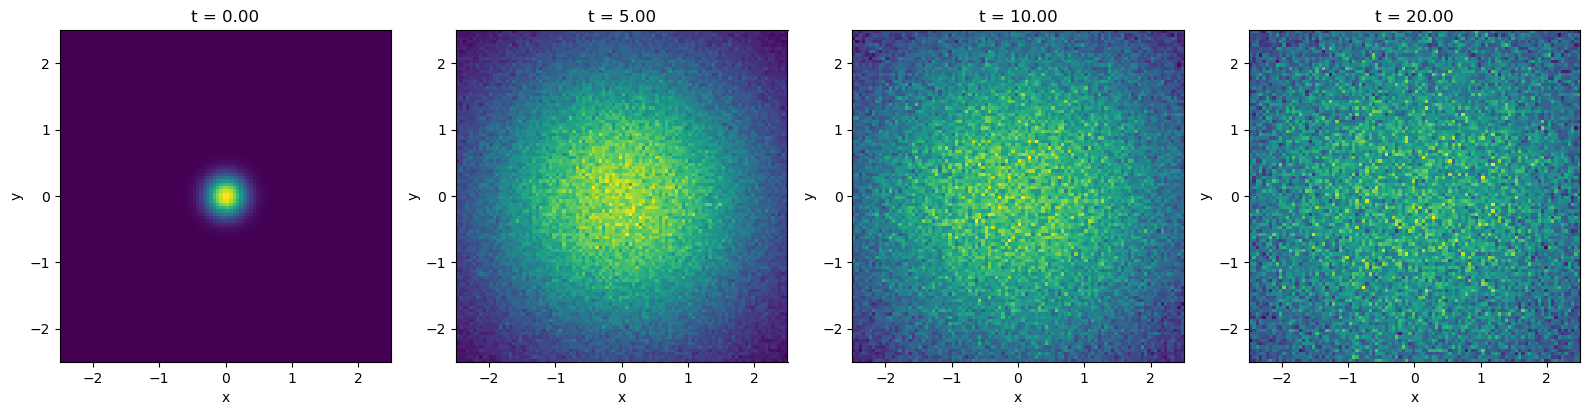

In [12]:
import numpy as np
import matplotlib.pyplot as plt

n_saves, n_bins, L = 100, 100, 2.5

counts = np.fromfile("camel_counts.bin", dtype=np.int64)
counts = counts.reshape(n_saves + 1, n_bins, n_bins)
t_history = np.fromfile("camel_t.bin", dtype=np.float64)

bin_area = (2 * L / n_bins) ** 2
P_history = counts / (counts.sum(axis=(1, 2), keepdims=True) * bin_area)

frames = [0, 25, 50, 100]
fig, axes = plt.subplots(1, len(frames), figsize=(4 * len(frames), 4))
#fig, axes = plt.subplots(len(frames), 1, figsize=(4, 4 * len(frames)))
for ax, k in zip(axes, frames):
    ax.imshow(P_history[k].T, origin="lower", extent=[-L, L, -L, L], cmap="viridis")
    ax.set_title(f"t = {t_history[k]:.2f}")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
plt.tight_layout()
plt.show()

In [9]:
print(np.fromfile("camel_t.bin", dtype=np.float64)[-1])

20.0


In [11]:
print(counts.sum(axis=(1, 2))[[0, 25, 50, 100]])

[1000000  779832  538919  324086]
